In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

In [2]:
df = pd.read_csv("./Obesity Classification.csv")
df

,ID,Age,Gender,Height,Weight,BMI,Label
0,1,25,Male,175,80,25.3,Normal Weight
1,2,30,Female,160,60,22.5,Normal Weight
2,3,35,Male,180,90,27.3,Overweight
3,4,40,Female,150,50,20.0,Underweight
4,5,45,Male,190,100,31.2,Obese
...,...,...,...,...,...,...,...
103,106,11,Male,175,10,3.9,Underweight
104,107,16,Female,160,10,3.9,Underweight
105,108,21,Male,180,15,5.6,Underweight
106,109,26,Female,150,15,5.6,Underweight


In [3]:
df.isnull().sum()

ID        0
Age       0
Gender    0
Height    0
Weight    0
BMI       0
Label     0
dtype: int64

In [4]:
df['Label'] = df['Label'].map({
    'Underweight':0,
    'Normal Weight':1,
    'Overweight':2,
    'Obese':3
})
df

,ID,Age,Gender,Height,Weight,BMI,Label
0,1,25,Male,175,80,25.3,1
1,2,30,Female,160,60,22.5,1
2,3,35,Male,180,90,27.3,2
3,4,40,Female,150,50,20.0,0
4,5,45,Male,190,100,31.2,3
...,...,...,...,...,...,...,...
103,106,11,Male,175,10,3.9,0
104,107,16,Female,160,10,3.9,0
105,108,21,Male,180,15,5.6,0
106,109,26,Female,150,15,5.6,0


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16564\2800363829.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[0, 0], palette="muted")
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16564\2800363829.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Label', y='BMI', ax=axes[1, 0], palette="Set3")
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16564\2800363829.py:29: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Label', y='Age', hue='Gender', ax=axes[1, 1], ci=None, palette="pastel")


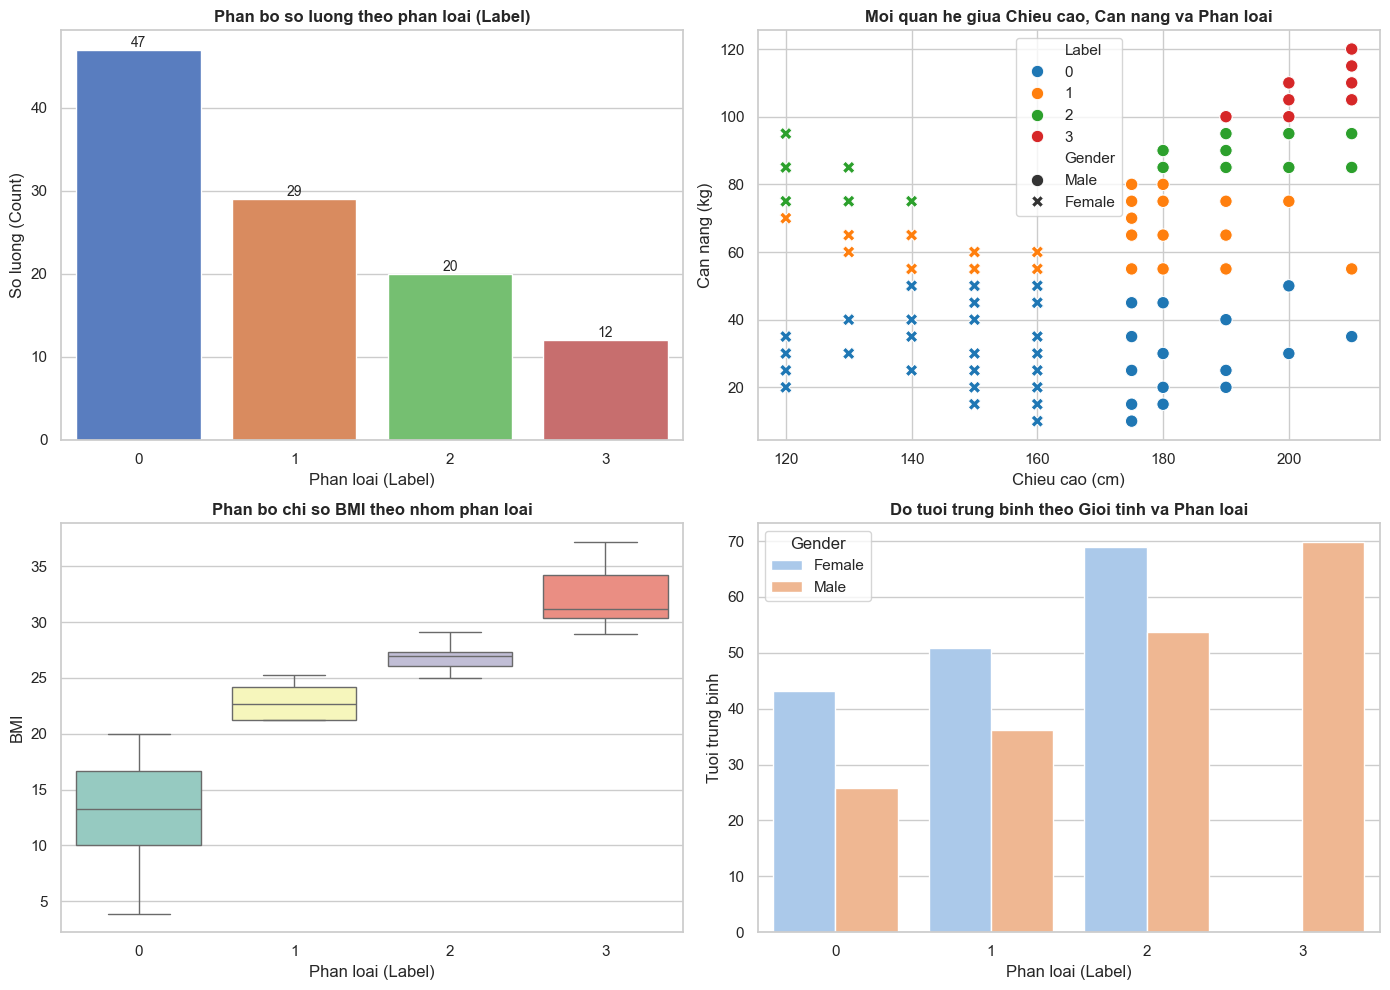

In [5]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})
# 7. Trực quan hóa dữ liệu bằng biểu đồ
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Biểu đồ 1: Số lượng theo từng nhóm Label
label_counts = df['Label'].value_counts()
sns.barplot(x=label_counts.index, y=label_counts.values, ax=axes[0, 0], palette="muted")
axes[0, 0].set_title("Phan bo so luong theo phan loai (Label)", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("So luong (Count)")
axes[0, 0].set_xlabel("Phan loai (Label)")
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Biểu đồ 2: Mối quan hệ Chiều cao, Cân nặng & Phân loại
sns.scatterplot(data=df, x='Height', y='Weight', hue='Label', style='Gender', s=80, ax=axes[0, 1], palette="tab10")
axes[0, 1].set_title("Moi quan he giua Chieu cao, Can nang va Phan loai", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Chieu cao (cm)")
axes[0, 1].set_ylabel("Can nang (kg)")

# Biểu đồ 3: Phân bố chỉ số BMI theo nhóm
sns.boxplot(data=df, x='Label', y='BMI', ax=axes[1, 0], palette="Set3")
axes[1, 0].set_title("Phan bo chi so BMI theo nhom phan loai", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Phan loai (Label)")
axes[1, 0].set_ylabel("BMI")

# Biểu đồ 4: Độ tuổi trung bình theo Giới tính và Phân loại
sns.barplot(data=df, x='Label', y='Age', hue='Gender', ax=axes[1, 1], ci=None, palette="pastel")
axes[1, 1].set_title("Do tuoi trung binh theo Gioi tinh va Phan loai", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Phan loai (Label)")
axes[1, 1].set_ylabel("Tuoi trung binh")

plt.tight_layout()
plt.show()

In [6]:
category_col = df.select_dtypes(include="object").columns 
category_col

Index(['Gender'], dtype='object')

In [7]:
df = pd.get_dummies(df, columns=category_col, drop_first=True) 
df

,ID,Age,Height,Weight,BMI,Label,Gender_Male
0,1,25,175,80,25.3,1,True
1,2,30,160,60,22.5,1,False
2,3,35,180,90,27.3,2,True
3,4,40,150,50,20.0,0,False
4,5,45,190,100,31.2,3,True
...,...,...,...,...,...,...,...
103,106,11,175,10,3.9,0,True
104,107,16,160,10,3.9,0,False
105,108,21,180,15,5.6,0,True
106,109,26,150,15,5.6,0,False


In [8]:
X = df.drop(columns=["Label"])
y = df["Label"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
X_train

,ID,Age,Height,Weight,BMI,Gender_Male
64,67,46,200,85,26.1,True
26,28,98,200,110,34.2,True
22,24,78,180,90,27.3,True
31,33,29,180,85,26.1,True
47,50,62,120,85,27.5,False
...,...,...,...,...,...,...
71,74,30,150,40,16.7,False
14,15,38,190,90,27.3,True
92,95,58,120,35,16.7,False
51,54,82,150,55,21.2,False


In [11]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [12]:
X_train

array([[ 0.33187703, -0.10795268,  1.25123106,  0.94936188,  0.77023864,
         1.        ],
       [-0.90217569,  1.98193648,  1.25123106,  1.8348838 ,  1.8550511 ,
         1.        ],
       [-1.0287452 ,  1.17813296,  0.53266097,  1.12646626,  0.9309516 ,
         1.        ],
       [-0.7439638 , -0.79118568,  0.53266097,  0.94936188,  0.77023864,
         1.        ],
       [-0.20604339,  0.53509014, -1.62304931,  0.94936188,  0.95773709,
        -1.        ],
       [ 1.47100261, -0.06776251, -1.26376426, -0.99878636, -0.94403289,
        -1.        ],
       [-1.28188422, -0.22852321, -0.90447922, -0.29036882, -0.04671888,
        -1.        ],
       [-0.30097052, -0.06776251,  1.25123106,  1.30357065,  0.89077336,
         1.        ],
       [ 1.09129408, -0.42947409, -0.90447922, -0.82168197, -0.48867951,
        -1.        ],
       [ 1.12293646, -0.22852321,  1.25123106, -0.29036882, -0.04671888,
         1.        ],
       [-1.47173848,  0.85661155, -1.62304931, -1.

In [13]:
model = LogisticRegression(max_iter=100)
model.fit(X_train, y_train)

c:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


LogisticRegression()

In [14]:
y_pred = model.predict(X_test)

In [15]:
accuracy_score(y_test, y_pred)

0.9090909090909091

In [16]:
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.9090909090909091
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       0.75      1.00      0.86         6
           2       1.00      0.50      0.67         4
           3       1.00      1.00      1.00         4

    accuracy                           0.91        22
   macro avg       0.94      0.88      0.88        22
weighted avg       0.93      0.91      0.90        22

